# Análisis de Resultados

Juan José H. Beltrán 𝄽 Ph.D. in Computer Sciences

In [1]:
# Start working from the root directory of the repository
import os
os.chdir('../')

In [ ]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

In [270]:
df_logs = pd.read_csv('solutions/logs.csv')
df_optimals = pd.read_csv('solutions/optimals.csv')
df_registry = pd.read_csv('instances/registry.csv')

In [278]:
df_registry.merge(df_optimals[pd.notna(df_optimals['makespan'])], how='inner', on='instance').groupby(['source', 'classification'])['instance'].count().reset_index()

,source,classification,instance
0,fisher-thompson1963,easy,2
1,fisher-thompson1963,hard,1
2,generated,easy,20
3,generated,toy,5
4,lawrence1984,easy,10
5,lawrence1984,hard,15
6,lawrence1984,medium,15


In [243]:
df_registry['ops'] = df_registry['jobs'] * df_registry['machines']

In [244]:
df_proc_logs = df_logs.merge(df_optimals[['instance', 'makespan']].rename({'makespan': 'optimal_makespan'}, axis=1), how='left', on='instance')
df_proc_logs['gap'] = (df_proc_logs['makespan'] - df_proc_logs['optimal_makespan'])/df_proc_logs['optimal_makespan']
df_proc_logs = df_proc_logs.merge(df_registry[['instance', 'horizon', 'jobs', 'machines']], how='left', on='instance')
df_proc_logs['ops'] = df_proc_logs['jobs'] * df_proc_logs['machines']
df_proc_logs['solution_found'] = (df_proc_logs['makespan'] != df_proc_logs['horizon']).astype(int)

In [245]:
df_proc_logs = df_proc_logs[pd.notna(df_proc_logs['gap'])]

In [246]:
df_proc_logs['runtime'] = df_proc_logs.apply(lambda x: 60 if x['runtime'] > 60 and x['algorithm'] != 'milp' else x['runtime'], axis=1)

In [247]:
df_proc_logs

,timestamp,algorithm,instance,time_limit,seed,makespan,runtime,expanded_nodes,weight,heuristic,...,initial_temp,cooling_rate,min_temp,optimal_makespan,gap,horizon,jobs,machines,ops,solution_found
0,2026-10-14 18:49:00,uninformed-dfs,ft06,60.0,NaN,112,60.000000,44366054.0,NaN,NaN,...,NaN,NaN,NaN,55.0,1.036364,197,6,6,36,1
1,2026-10-14 18:50:00,uninformed-dfs,ft10,60.0,NaN,2834,60.000000,30847875.0,NaN,NaN,...,NaN,NaN,NaN,930.0,2.047312,5109,10,10,100,1
2,2026-10-14 18:51:00,uninformed-dfs,ft20,60.0,NaN,3010,60.000000,17313245.0,NaN,NaN,...,NaN,NaN,NaN,1165.0,1.583691,5109,20,5,100,1
3,2026-10-14 18:52:00,uninformed-dfs,jb01,60.0,NaN,320,0.035835,26694.0,NaN,NaN,...,NaN,NaN,NaN,320.0,0.000000,624,3,4,12,1
4,2026-10-14 18:52:00,uninformed-dfs,jb02,60.0,NaN,279,0.048901,40072.0,NaN,NaN,...,NaN,NaN,NaN,279.0,0.000000,543,3,4,12,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1182,2026-10-21 18:30:11,milp,jb21,NaN,NaN,533,1.967504,NaN,NaN,NaN,...,NaN,NaN,NaN,533.0,0.000000,2345,7,7,49,1
1183,2026-10-21 18:32:40,milp,jb22,NaN,NaN,771,1.328919,NaN,NaN,NaN,...,NaN,NaN,NaN,771.0,0.000000,3115,6,10,60,1
1184,2026-10-21 18:34:21,milp,jb23,NaN,NaN,667,12.501041,NaN,NaN,NaN,...,NaN,NaN,NaN,667.0,0.000000,3400,8,8,64,1
1185,2026-10-21 18:41:01,milp,jb24,NaN,NaN,658,61.540673,NaN,NaN,NaN,...,NaN,NaN,NaN,658.0,0.000000,3127,9,7,63,1


In [248]:
experiment_ids = ['algorithm', 'seed', 'weight', 'heuristic', 'beam_width', 'neighborhood', 'cooling_rate']

In [249]:
df_grpd_logs = df_proc_logs.groupby(experiment_ids, dropna=False).agg(
    num_instances = ('instance', 'count'),
    mean_runtime=('runtime', 'mean'),
    mean_gap=('gap', 'mean'),
    instances_with_solution = ('solution_found', 'sum')
).reset_index()

## General Results Table

# Análisis

In [250]:
df_proc_logs = df_proc_logs[df_proc_logs['solution_found'] == 1]

In [251]:
_experiment_colors = {}
_experiment_color_palette = plt.get_cmap('turbo')
for index, experiment in enumerate(df_grpd_logs[experiment_ids].to_dict('records')):
    color_key = tuple((column, repr(experiment[column])) for column in experiment_ids)
    _experiment_colors[color_key] = _experiment_color_palette(
        index / max(len(df_grpd_logs) - 1, 1)
    )

In [252]:
def plot_experiments(experiments):
    """Plot runs from df_proc_logs, colored by experiment.

    Each item should be a dict or pandas Series containing the columns in
    experiment_ids, such as a record from df_grpd_logs.
    """
    hgt = 0.5

    if isinstance(experiments, pd.DataFrame):
        experiments = experiments.to_dict('records')
    else:
        experiments = list(experiments)

    fig, ax = plt.subplots(figsize=(16, 9))

    for experiment in experiments:
        if isinstance(experiment, pd.Series):
            experiment = experiment.to_dict()

        missing_columns = [column for column in experiment_ids if column not in experiment]
        if missing_columns:
            raise ValueError(f"Experiment is missing identity columns: {missing_columns}")

        mask = pd.Series(True, index=df_proc_logs.index)
        for column in experiment_ids:
            value = experiment[column]
            if pd.isna(value):
                mask &= df_proc_logs[column].isna()
            else:
                mask &= df_proc_logs[column].eq(value)

        runs = df_proc_logs.loc[mask]
        if runs.empty:
            raise ValueError(f"No runs found for experiment: {experiment}")

        label_parts = [
            f'{column}: {experiment[column]}'
            for column in experiment_ids
            if not pd.isna(experiment[column])
        ]
        label = '; '.join(label_parts)
        color_key = tuple((column, repr(experiment[column])) for column in experiment_ids)
        if color_key not in _experiment_colors:
            color_index = len(_experiment_colors)
            _experiment_colors[color_key] = _experiment_color_palette(
                color_index / max(color_index + 1, 1)
            )

        ax.scatter(
            runs['gap'],
            runs['runtime'],
            s=runs['ops'],
            color=_experiment_colors[color_key],
            label=label,
            alpha=0.65,
            edgecolors='white',
            linewidths=0.5,
        )

    ax.set_xlabel('Relative Gap')
    ax.set_ylabel('Runtime (Seconds)')
    ax.set_title(f'Runtime vs. Relative Gap Per Execution ({len(runs[pd.notna(runs['gap'])])} solutions found)')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.text(
        0.5,
        hgt,
        'Marker area is proportional to instance operations.',
        transform=ax.transAxes,
        ha='center',
        va='bottom',
        fontsize=9,
    )
    if experiments:
        ax.legend(title='Experiment', loc='lower center', bbox_to_anchor=(0.5, hgt + 0.02), ncol=2)
    fig.tight_layout()
    return ax

<Axes: title={'center': 'Runtime vs. Relative Gap Per Execution (3 solutions found)'}, xlabel='Relative Gap', ylabel='Runtime (Seconds)'>

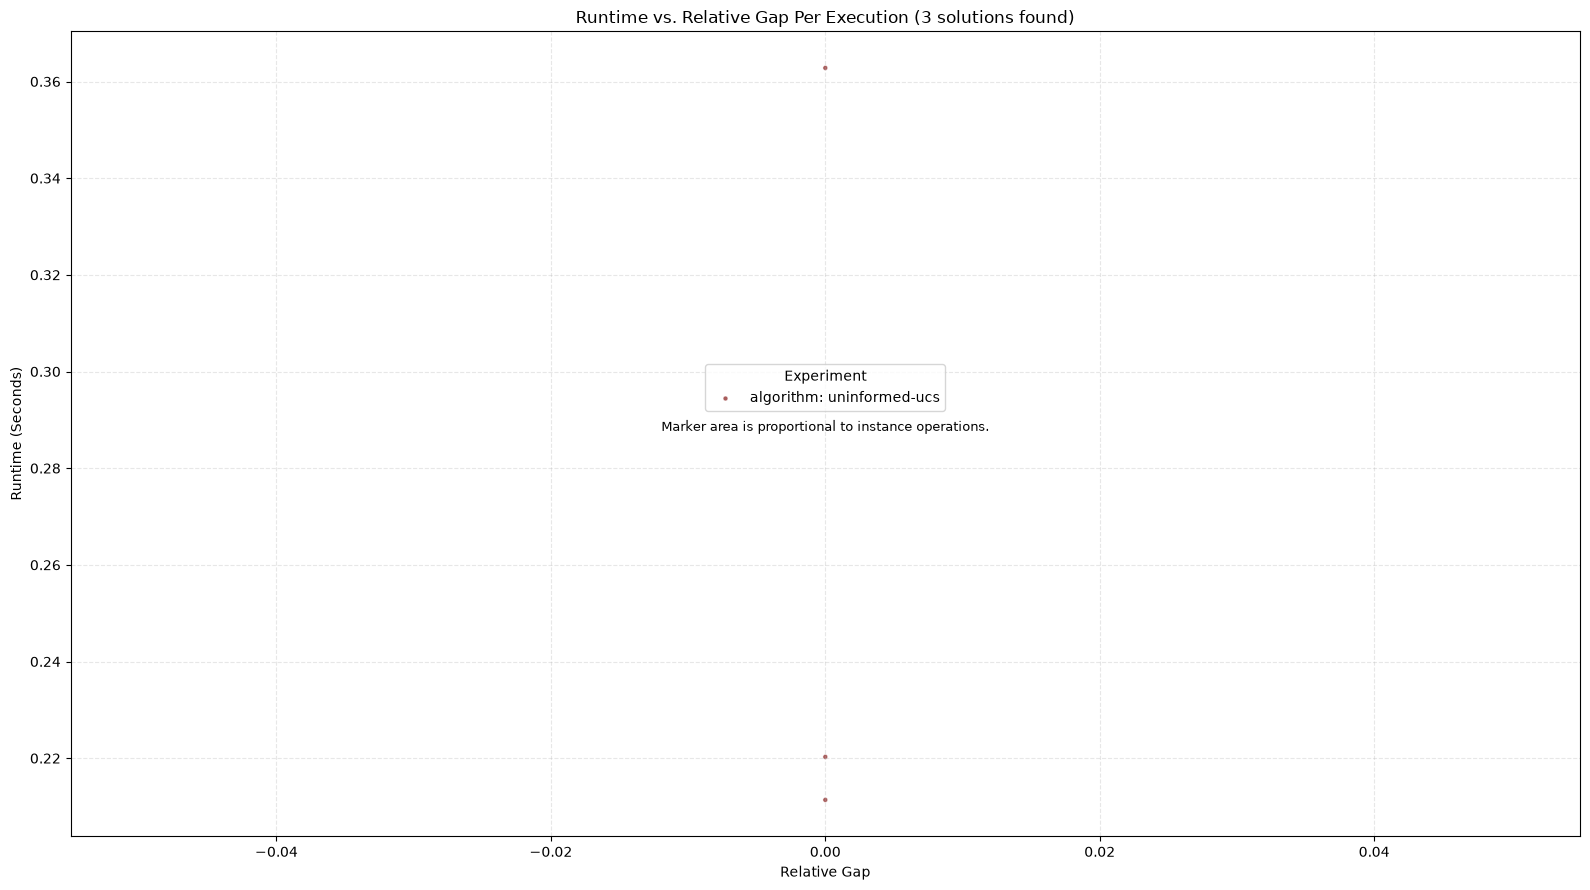

In [268]:
# Compare two heuristic-wa experiments, each run across all 83 instances.
experiments = df_grpd_logs[df_grpd_logs.index.isin([14])]

#assert len(experiments) == 2
#assert (experiments['num_instances'] == 83).all()

plot_experiments(experiments.to_dict('records'))

In [254]:
# Compare two heuristic-wa experiments, each run across all 83 instances.
# experiments = df_grpd_logs.loc[
#     (df_grpd_logs['algorithm'] == 'heuristic-wa')
#     & (df_grpd_logs['weight'] == 1)
#     & df_grpd_logs['heuristic'].isin([
#         'combined_bound_heuristic',
#         'mwrm_heuristic',
#     ])
# ]

# #assert len(experiments) == 2
# #assert (experiments['num_instances'] == 83).all()

# plot_experiments(experiments.to_dict('records'))